# Tamaño de muestra y número de árboles — LightGBM

Complemento de la semana 11. Los notebooks 02 a 04 entrenan con el 20 % de cada mes (`SAMPLE_FRAC = 0.20`) por límite de cómputo (proposal.md, sección 12). Aquí medimos si el modelo elegido en el notebook 04 mejora con más datos y, como sí mejora, recalculamos su número de árboles para entrenar con el 50 %.

El notebook 04 no se modifica: sus resultados siguen siendo una comparación válida entre modelos con el 20 %. Se mantiene el mismo protocolo de validación:

- Las decisiones se toman con **validación cruzada temporal dentro de enero-abril**.
- **Mayo** solo compara configuraciones finales, siempre con la misma muestra que los notebooks 02 a 04.
- **Junio** (test) no se toca.

Además, en la sección 3 se entrena HistGradientBoosting con la configuración elegida para LightGBM, para comprobar si la elección de LightGBM del notebook 03 depende del algoritmo o solo de la configuración.

Tarda cerca de 40 minutos y necesita unos 8 GB de RAM.

In [1]:
import sys
sys.path.append('..')

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.ensemble import HistGradientBoostingRegressor

from src.data import cargar_mes, limpiar_mes
from src.features import construir_preprocesador, preparar_xy
from src import tuning

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

import src.features as features
features.RUTA_ZONAS = Path('../data/Taxi_Zone_Lookup.csv')
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

with open('../outputs/mejores_hiperparametros.json', encoding='utf-8') as f:
    cfg = json.load(f)
N_ARBOLES_20 = cfg['n_estimators']
print(f"Configuración del notebook 04: {cfg['params']} | {N_ARBOLES_20} árboles")

Configuración del notebook 04: {'objective': 'regression_l1', 'learning_rate': 0.05, 'num_leaves': 281, 'min_child_samples': 30, 'subsample': 0.78, 'colsample_bytree': 0.685, 'reg_alpha': 5.094, 'reg_lambda': 0.3762} | 1219 árboles


## 1. Carga de datos

Cada mes se carga y limpia una sola vez con `src/data.py`, y las muestras se toman en memoria con la misma regla que `cargar_todo` (muestreo por mes con `random_state`). No se usa `cargar_todo` directamente porque reescribe `reports/limpieza_reglas.csv` en cada llamada.

Mayo se muestrea al 20 % con `SEED = 42`: es exactamente la muestra de validación de los notebooks 02 a 04.

In [2]:
def mes_limpio(month):
    df, _ = limpiar_mes(cargar_mes(2025, month), 2025, month)
    return df

meses_train = {m: mes_limpio(m) for m in (1, 2, 3, 4)}
val = mes_limpio(5).sample(frac=0.20, random_state=SEED)

def muestra_train(frac, seed=SEED):
    return pd.concat(
        [meses_train[m].sample(frac=frac, random_state=seed) for m in (1, 2, 3, 4)],
        ignore_index=True,
    )

X_val, _ = preparar_xy(val)
y_val = val['trip_duration_min'].to_numpy(dtype=float)
print(f"Enero-abril limpio: {sum(len(d) for d in meses_train.values()):,} viajes")
print(f"Val (mayo, 20 %):   {len(val):,} viajes")

Enero-abril limpio: 14,362,208 viajes
Val (mayo, 20 %):   855,412 viajes


## 2. Curva de tamaño de muestra

Se entrena la configuración elegida en el notebook 04 (modelo J, 1219 árboles fijos) cambiando solo la fracción de enero-abril. El 20 % se repite con otra semilla para medir cuánto varía el MAE solo por la muestra elegida: una diferencia entre fracciones menor que esa variación no significaría nada.

La fila de 20 % con `SEED = 42` debe reproducir el MAE del modelo J (4.015 min) y funciona como control.

También se registra el MAE con 400 y 800 árboles. Es solo un diagnóstico para ver si con más datos el modelo sigue mejorando al agregar árboles; el número de árboles no se elige con mayo, sino en la sección 4.

In [3]:
CHECKPOINTS = [400, 800, N_ARBOLES_20]

def entrenar_fraccion(frac, seed):
    X_tr, y_tr_log = preparar_xy(muestra_train(frac, seed), usar_log_target=True)
    t0 = time.time()
    prep = construir_preprocesador(escalar_numericas=False)
    Xt_tr = prep.fit_transform(X_tr, y_tr_log).astype(np.float32)
    Xt_val = prep.transform(X_val).astype(np.float32)
    modelo = lgb.LGBMRegressor(n_estimators=N_ARBOLES_20, **tuning.PARAMS_FIJOS, **cfg['params'])
    modelo.fit(Xt_tr, y_tr_log)
    fila = {'frac': frac, 'seed': seed, 'filas_train': len(X_tr), 'segundos': round(time.time() - t0, 1)}
    for k in CHECKPOINTS:
        m = tuning.metricas(y_val, np.expm1(modelo.predict(Xt_val, num_iteration=k)))
        fila[f'MAE_{k}'] = m['MAE']
    fila['RMSLE'] = m['RMSLE']
    print(f"{frac:.0%} (seed {seed}): {len(X_tr):>9,} filas | MAE = {fila[f'MAE_{N_ARBOLES_20}']:.4f} | "
          f"RMSLE = {fila['RMSLE']:.4f} | {fila['segundos']:.0f} s")
    return fila

curva = pd.DataFrame([entrenar_fraccion(f, s) for f, s in [(0.10, SEED), (0.20, SEED), (0.20, 7), (0.50, SEED)]])

control = curva.query('frac == 0.20 and seed == @SEED')[f'MAE_{N_ARBOLES_20}'].item()
assert abs(control - cfg['val_mayo']['MAE']) < 1e-3, "No se reproduce el modelo J del notebook 04"
print(f"\nControl OK: el 20 % reproduce el MAE del notebook 04 ({control:.4f})")
curva

10% (seed 42): 1,436,221 filas | MAE = 4.1282 | RMSLE = 0.3258 | 54 s


20% (seed 42): 2,872,441 filas | MAE = 4.0154 | RMSLE = 0.3183 | 93 s


20% (seed 7): 2,872,441 filas | MAE = 4.0182 | RMSLE = 0.3183 | 92 s


50% (seed 42): 7,181,104 filas | MAE = 3.9281 | RMSLE = 0.3130 | 220 s

Control OK: el 20 % reproduce el MAE del notebook 04 (4.0154)


,frac,seed,filas_train,segundos,MAE_400,MAE_800,MAE_1219,RMSLE
0,0.1,42,1436221,53.7,4.160711,4.138127,4.128202,0.325826
1,0.2,42,2872441,92.8,4.060441,4.028878,4.015426,0.318324
2,0.2,7,2872441,91.5,4.064323,4.031135,4.018209,0.318276
3,0.5,42,7181104,220.0,3.984842,3.944264,3.928109,0.312964


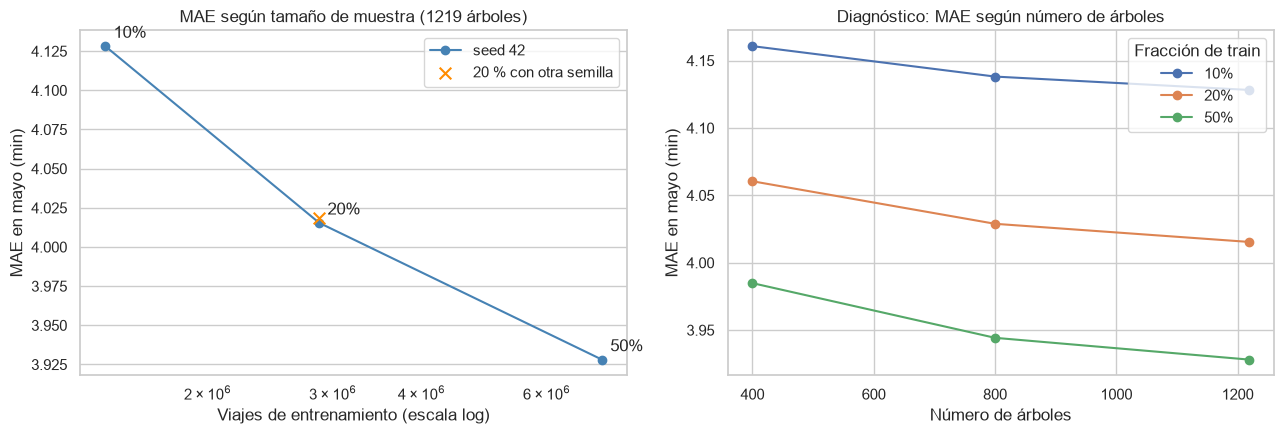

In [4]:
principal = curva[curva['seed'] == SEED]
otra_semilla = curva[curva['seed'] != SEED]
col = f'MAE_{N_ARBOLES_20}'

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(principal['filas_train'], principal[col], marker='o', color='steelblue', label=f'seed {SEED}')
axes[0].scatter(otra_semilla['filas_train'], otra_semilla[col], marker='x', s=70, color='darkorange',
                label='20 % con otra semilla', zorder=3)
for _, r in principal.iterrows():
    axes[0].annotate(f"{r['frac']:.0%}", (r['filas_train'], r[col]), textcoords='offset points', xytext=(6, 6))
axes[0].set_xscale('log')
axes[0].set_xlabel('Viajes de entrenamiento (escala log)')
axes[0].set_ylabel('MAE en mayo (min)')
axes[0].set_title(f'MAE según tamaño de muestra ({N_ARBOLES_20} árboles)')
axes[0].legend()

for _, r in principal.iterrows():
    axes[1].plot(CHECKPOINTS, [r[f'MAE_{k}'] for k in CHECKPOINTS], marker='o', label=f"{r['frac']:.0%}")
axes[1].set_xlabel('Número de árboles')
axes[1].set_ylabel('MAE en mayo (min)')
axes[1].set_title('Diagnóstico: MAE según número de árboles')
axes[1].legend(title='Fracción de train')
plt.tight_layout()
plt.savefig('../reports/figures/08_tamano_muestra.png', dpi=150)
plt.show()

## 3. Chequeo: HistGradientBoosting con la configuración de LightGBM

En el notebook 03, HistGradientBoosting quedó 0.05 min detrás de LightGBM (4.13 contra 4.07), pero con una configuración más chica (63 hojas por árbol contra 127, sin submuestreo). Aquí se entrena con la configuración del modelo J traducida a scikit-learn, sobre la misma muestra del 20 % y el mismo preprocesamiento:

| LightGBM (J) | HistGradientBoosting |
|---|---|
| `objective='regression_l1'` | `loss='absolute_error'` |
| `learning_rate`, `n_estimators` | `learning_rate`, `max_iter` |
| `num_leaves` | `max_leaf_nodes` |
| `min_child_samples` | `min_samples_leaf` |
| `reg_lambda` | `l2_regularization` |
| `colsample_bytree` (por árbol) | `max_features` (por división) |

La traducción es aproximada: HistGradientBoosting no tiene submuestreo de filas (`subsample`) ni regularización L1 (`reg_alpha`), y muestrea columnas en cada división en lugar de en cada árbol. Los tiempos incluyen el preprocesamiento en ambos casos.

In [5]:
p = cfg['params']
assert p['objective'] == 'regression_l1'

t0 = time.time()
X_tr, y_tr_log = preparar_xy(muestra_train(0.20), usar_log_target=True)
prep = construir_preprocesador(escalar_numericas=False)
Xt_tr = prep.fit_transform(X_tr, y_tr_log).astype(np.float32)
Xt_val = prep.transform(X_val).astype(np.float32)
hgb = HistGradientBoostingRegressor(
    loss='absolute_error',
    learning_rate=p['learning_rate'],
    max_iter=N_ARBOLES_20,
    max_leaf_nodes=p['num_leaves'],
    min_samples_leaf=p['min_child_samples'],
    l2_regularization=p['reg_lambda'],
    max_features=p['colsample_bytree'],
    early_stopping=False,
    random_state=SEED,
)
hgb.fit(Xt_tr, y_tr_log)
segundos_hgb = round(time.time() - t0, 1)
m_hgb = tuning.metricas(y_val, np.expm1(hgb.predict(Xt_val)))
del X_tr, Xt_tr, Xt_val, hgb

fila_20 = curva.query('frac == 0.20 and seed == @SEED').iloc[0]
chequeo_hgb = [
    {'modelo': 'J: LightGBM (notebook 04)', 'MAE': float(fila_20[f'MAE_{N_ARBOLES_20}']),
     'RMSLE': float(fila_20['RMSLE']), 'segundos': float(fila_20['segundos'])},
    {'modelo': 'HistGradientBoosting, configuración de J', **m_hgb, 'segundos': segundos_hgb},
]
pd.DataFrame(chequeo_hgb)

,modelo,MAE,RMSLE,segundos
0,J: LightGBM (notebook 04),4.015426,0.318324,92.8
1,"HistGradientBoosting, configuración de J",4.031651,0.319057,275.8


## 4. Número de árboles con el 50 %

Los 1219 árboles se eligieron con el 20 %. Con más datos el modelo puede aprovechar más árboles, así que se recalculan con el mismo procedimiento de la sección 6 del notebook 04: early stopping (paciencia 30, hasta 6000 árboles) sobre los folds de `TimeSeriesSplit(n_splits=3)` de enero-abril, ahora con el 50 %. El resto de los hiperparámetros no cambia.

No se repite la búsqueda completa: tomaría más de 2 horas y en el notebook 04 la búsqueda rindió poco (0.06 min de MAE).

In [6]:
FRAC_FINAL = 0.50
PACIENCIA = 30

train = muestra_train(FRAC_FINAL)
del meses_train

t0 = time.time()
folds = tuning.preparar_folds(train, n_splits=3)
print(f"Folds preparados en {time.time() - t0:.0f} s | {len(folds[0]['nombres'])} features")
tuning.resumen_folds(folds)

Folds preparados en 32 s | 41 features


,fold,filas_train,train,filas_val,val
0,1,1795276,01-Jan a 03-Feb,1795276,03-Feb a 04-Mar
1,2,3590552,01-Jan a 04-Mar,1795276,04-Mar a 02-Apr
2,3,5385828,01-Jan a 02-Apr,1795276,02-Apr a 30-Apr


In [7]:
r50 = tuning.evaluar_config(cfg['params'], folds, excluir=tuple(cfg['features_excluidas']),
                            max_arboles=6000, paciencia=PACIENCIA)
N_ARBOLES_50 = int(round(np.mean(r50['arboles_por_fold'])))
del folds

print(f"MAE validación cruzada: 20 % = {cfg['cv_MAE']:.4f} | 50 % = {r50['cv_MAE']:.4f}")
print(f"Árboles por fold con 50 %: {r50['arboles_por_fold']} -> {N_ARBOLES_50} (antes {N_ARBOLES_20})")

MAE validación cruzada: 20 % = 3.4488 | 50 % = 3.3587
Árboles por fold con 50 %: [1074, 2018, 2038] -> 1710 (antes 1219)


## 5. Comparación final sobre mayo

Se reajusta el preprocesador con el 50 % de enero-abril y se comparan tres versiones de la misma configuración:

- **J**: modelo elegido en el notebook 04 (20 %, 1219 árboles).
- **J con 50 %**: mismos 1219 árboles, más datos (de la sección 2).
- **K**: 50 % con el número de árboles recalculado en la sección 4.

In [8]:
X_tr, y_tr_log = preparar_xy(train, usar_log_target=True)
del train
prep = construir_preprocesador(escalar_numericas=False)
Xt_tr = prep.fit_transform(X_tr, y_tr_log).astype(np.float32)
Xt_val = prep.transform(X_val).astype(np.float32)
del X_tr

t0 = time.time()
modelo_k = lgb.LGBMRegressor(n_estimators=N_ARBOLES_50, **tuning.PARAMS_FIJOS, **cfg['params'])
modelo_k.fit(Xt_tr, y_tr_log)
segundos_k = round(time.time() - t0, 1)
m_k = tuning.metricas(y_val, np.expm1(modelo_k.predict(Xt_val)))

fila_50 = curva.query('frac == @FRAC_FINAL and seed == @SEED').iloc[0]
resultados = [
    {'modelo': 'J: LightGBM ajustado, 20 % (notebook 04)', **cfg['val_mayo'], 'arboles': N_ARBOLES_20},
    {'modelo': 'J con 50 %, mismos árboles', 'MAE': float(fila_50[col]), 'RMSLE': float(fila_50['RMSLE']),
     'arboles': N_ARBOLES_20},
    {'modelo': 'K: J con 50 % y árboles recalculados', **m_k, 'arboles': N_ARBOLES_50,
     'segundos_entrenamiento': segundos_k},
]
tabla = pd.DataFrame(resultados)
mae_j = tabla.loc[0, 'MAE']
tabla['mejora_vs_J_%'] = ((mae_j - tabla['MAE']) / mae_j * 100).round(1)

assert tabla['MAE'].min() >= 2, "MAE sospechosamente bajo: auditar features por leakage"
print("OK: ningún modelo baja de 2 min de MAE (chequeo de sanidad de leakage)")
tabla

OK: ningún modelo baja de 2 min de MAE (chequeo de sanidad de leakage)


,modelo,MAE,RMSLE,arboles,segundos_entrenamiento,mejora_vs_J_%
0,"J: LightGBM ajustado, 20 % (notebook 04)",4.015426,0.318324,1219,NaN,0.0
1,"J con 50 %, mismos árboles",3.928109,0.312964,1219,NaN,2.2
2,K: J con 50 % y árboles recalculados,3.918025,0.312452,1710,321.6,2.4


## 6. Guardado de resultados

- `outputs/metrics_tamano_muestra.json`: curva de tamaño de muestra, chequeo de HistGradientBoosting y comparación sobre mayo.
- `outputs/config_modelo_final.json`: configuración para la semana 12 (hiperparámetros del notebook 04, 50 % de cada mes y número de árboles recalculado). `outputs/mejores_hiperparametros.json` no se modifica.

In [9]:
with open('../outputs/metrics_tamano_muestra.json', 'w', encoding='utf-8') as f:
    json.dump({'curva': curva.to_dict(orient='records'), 'chequeo_hgb': chequeo_hgb,
               'comparacion_mayo': resultados},
              f, indent=2, ensure_ascii=False)

config_final = {
    'modelo': 'LightGBM',
    'params': cfg['params'],
    'n_estimators': N_ARBOLES_50,
    'params_fijos': tuning.PARAMS_FIJOS,
    'target': cfg['target'],
    'features_excluidas': cfg['features_excluidas'],
    'sample_frac': FRAC_FINAL,
    'seed': SEED,
    'cv_MAE': r50['cv_MAE'],
    'cv_RMSLE': r50['cv_RMSLE'],
    'val_mayo': m_k,
    'origen': 'params de outputs/mejores_hiperparametros.json (notebook 04); n_estimators recalculado con 50 % en notebook 04b',
    'validacion': f'TimeSeriesSplit(n_splits=3) sobre enero-abril, SAMPLE_FRAC={FRAC_FINAL}, SEED={SEED}',
}
with open('../outputs/config_modelo_final.json', 'w', encoding='utf-8') as f:
    json.dump(config_final, f, indent=2, ensure_ascii=False)
print("Guardado: outputs/metrics_tamano_muestra.json, outputs/config_modelo_final.json")

Guardado: outputs/metrics_tamano_muestra.json, outputs/config_modelo_final.json


## 7. Lectura de resultados

Resultados sobre validación (mayo), siempre con la misma muestra de mayo que los notebooks 02 a 04:

| Modelo | Train | Árboles | MAE (min) | RMSLE |
|---|---|---|---|---|
| J. LightGBM ajustado (notebook 04) | 20 % | 1219 | 4.015 | 0.3183 |
| J con 50 % | 50 % | 1219 | 3.928 | 0.3130 |
| **K. J con 50 % y árboles recalculados** | **50 %** | **1710** | **3.918** | **0.3125** |

**Más datos mejoran el modelo más que la búsqueda de hiperparámetros.** Pasar del 20 % al 50 % de cada mes baja el MAE en mayo de 4.015 a 3.918 min (−2.4 %), sin cambiar ningún hiperparámetro salvo el número de árboles. Toda la búsqueda del notebook 04 había bajado el MAE de 4.072 a 4.015 (−1.4 %).

**La mejora es real, no ruido de muestreo.** Repetir el 20 % con otra semilla cambia el MAE en 0.003 min; la diferencia entre 20 % y 50 % es unas 30 veces mayor. El control (20 % con `SEED = 42`) reproduce exactamente el MAE del notebook 04.

**La ganancia por más datos disminuye, pero no se agota.** Duplicar la muestra de 10 % a 20 % baja el MAE 0.113 min; pasar de 20 % a 50 % (2.5 veces más datos) lo baja 0.087. No se mide el 100 % porque necesitaría unos 12-13 GB de RAM, más de lo disponible en la laptop.

**Con más datos el modelo aprovecha más árboles.** En el diagnóstico (figura, panel derecho) el MAE con 50 % seguía bajando entre 800 y 1219 árboles. El early stopping sobre los folds de enero-abril con el 50 % eleva el número de árboles de 1219 a 1710 y el MAE de validación cruzada baja de 3.45 a 3.36. El efecto de recalcular los árboles sobre mayo es pequeño (0.010 min); casi toda la mejora viene de los datos.

**LightGBM se mantiene frente a HistGradientBoosting.** Con la configuración de J traducida, HistGradientBoosting llega a 4.032 min de MAE contra 4.015 de LightGBM, sobre los mismos datos. La diferencia del notebook 03 (0.05 min) se reduce a 0.016 min: la mayor parte venía de la configuración y no del algoritmo. LightGBM sigue algo mejor y entrena 3 veces más rápido (93 s contra 276 s, preprocesamiento incluido), así que la elección del notebook 03 se sostiene. La traducción es aproximada: HistGradientBoosting no tiene submuestreo de filas ni regularización L1.

**Limitaciones.**
- Los 1710 árboles son el promedio de folds que entrenan con menos datos que el 50 % completo (el fold más grande usa 5.4 millones de viajes contra 7.2 millones), así que todavía pueden quedar algo cortos.
- Los demás hiperparámetros se eligieron con el 20 % y no se volvieron a buscar con el 50 %.
- Mayo ya se usó para comparar varios modelos, así que su MAE no es una estimación del todo limpia. La estimación final es la de junio.

**Siguientes pasos (semana 12):** entrenar el modelo K con la configuración de `outputs/config_modelo_final.json` (50 % de cada mes, 1710 árboles) y evaluarlo una sola vez sobre junio. Para que la comparación final sea justa, los baselines se reentrenan con la misma muestra del 50 % y se evalúan también sobre junio.

Las métricas de este notebook están en `outputs/metrics_tamano_muestra.json` y la configuración para la semana 12 en `outputs/config_modelo_final.json`.